# Stock Market Analysis

## Get Data
Downloading data from yahoo finance

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Range of data
Period = "3mo"

# Downloading data. auto_adjust=True (split/dividend-adjusted OHLC) is set explicitly so results
# don't change with the yfinance version's default.
data = yf.download(['MSFT', 'AAPL', 'GOOG'], period=Period, auto_adjust=True, progress=False)

## Draw Price Charts
Function to draw the close price with a simple moving average (SMA, length in bars)

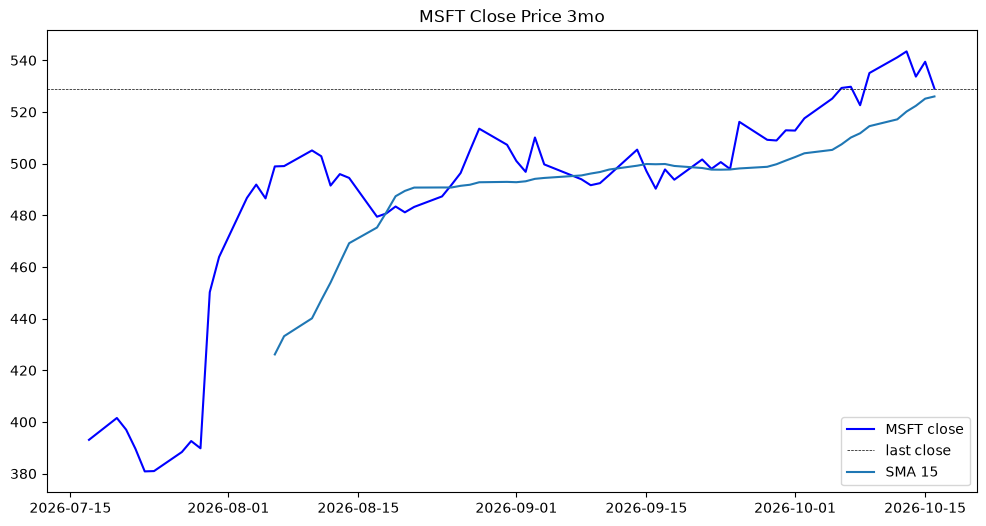

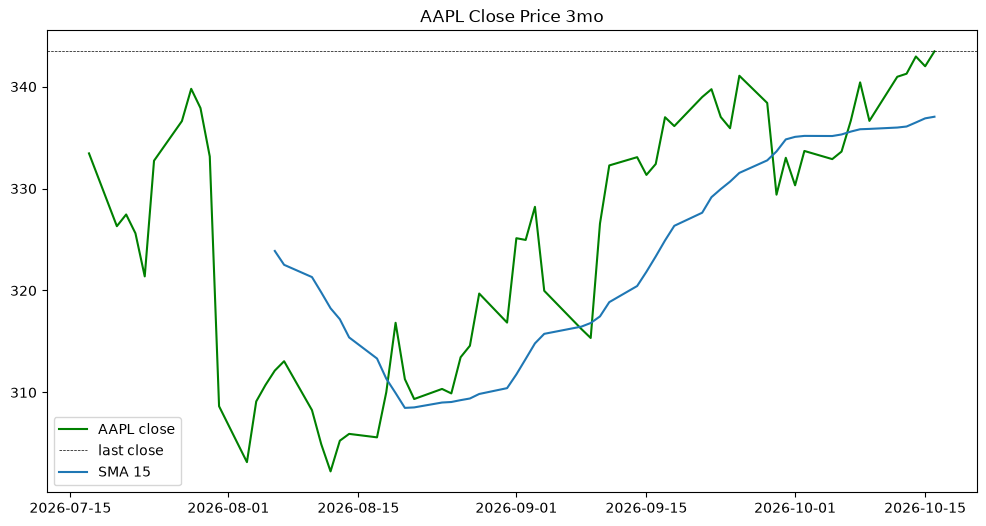

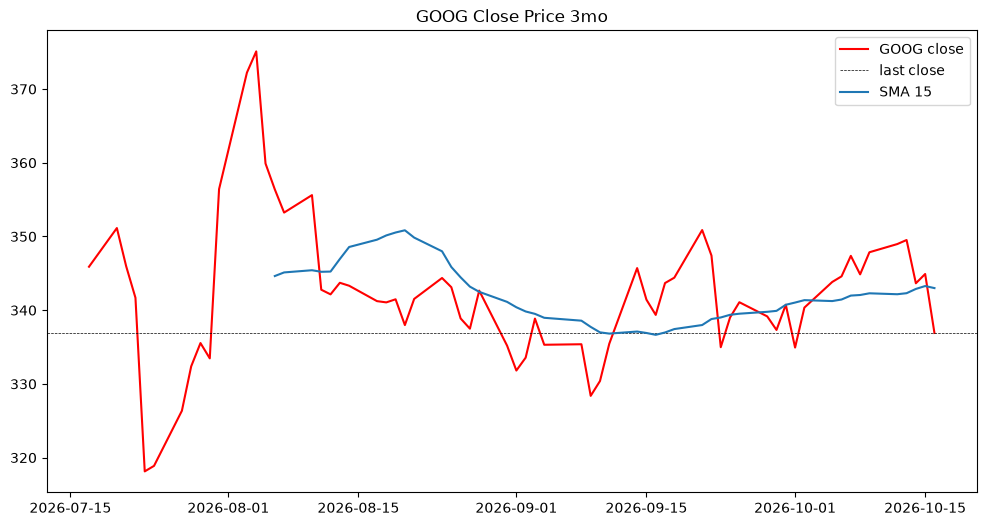

In [2]:
def draw_chart(x, y, symbol, color, length, period):
    plt.figure(figsize=(12, 6))
    plt.plot(x, y, color, label=f"{symbol} close")
    plt.title(f"{symbol} Close Price {period}")
    plt.axhline(y.iloc[-1], color='black', linestyle='--', linewidth=0.5, label="last close")

    # Simple moving average
    sma_ = y.rolling(window=length).mean()
    plt.plot(x, sma_, label=f"SMA {length}")
    plt.legend()

sma_len = 15
for symbol, color in [("MSFT", "b"), ("AAPL", "g"), ("GOOG", "r")]:
    draw_chart(data.index, data["Close", symbol], symbol, color, sma_len, Period)


## Rolling (causal) Z-score of the close
Z = (close − rolling mean) / rolling std over the last `z_len` bars. Each value uses only that bar and earlier ones, so past values never change when new data arrives and they don't depend on the chosen `Period`. (A Z-score over the whole downloaded window would use future bars.) The first `z_len − 1` bars have no value.

{'MSFT': 0.6, 'AAPL': 1.44, 'GOOG': -1.22}


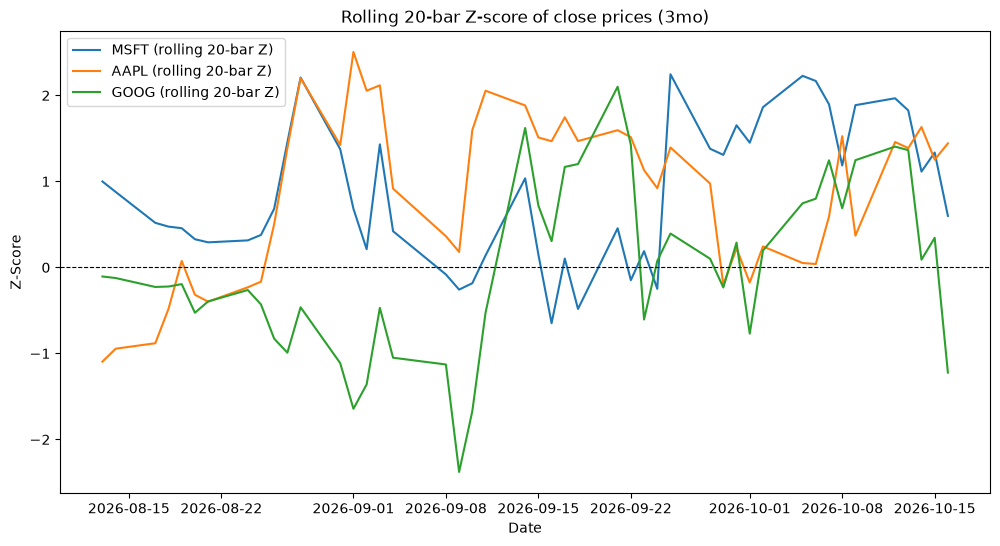

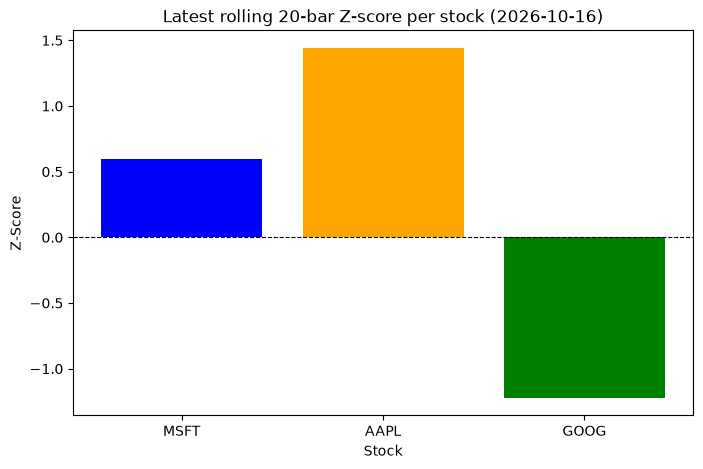

In [3]:
# Rolling Z-score (causal)
z_len = 20   # bars

def rolling_z(series, n):
    return (series - series.rolling(n).mean()) / series.rolling(n).std()

data_zscore = pd.DataFrame({t: rolling_z(data['Close', t], z_len) for t in ['MSFT', 'AAPL', 'GOOG']})
last_zscores = data_zscore.iloc[-1].to_dict()
print({k: round(v, 2) for k, v in last_zscores.items()})

# Plot 1: Z-Score Over Time
plt.figure(figsize=(12, 6))
for t in data_zscore:
    plt.plot(data_zscore.index, data_zscore[t], label=f'{t} (rolling {z_len}-bar Z)')
plt.title(f'Rolling {z_len}-bar Z-score of close prices ({Period})')
plt.xlabel('Date')
plt.ylabel('Z-Score')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)  # Reference line at Z=0
plt.legend()
plt.show()

# Plot 2: latest Z-score per stock (bar chart)
plt.figure(figsize=(8, 5))
plt.bar(last_zscores.keys(), last_zscores.values(), color=['blue', 'orange', 'green'])
plt.title(f'Latest rolling {z_len}-bar Z-score per stock ({data.index[-1]:%Y-%m-%d})')
plt.ylabel('Z-Score')
plt.xlabel('Stock')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)  # Reference line at Z=0
plt.show()


## Estimated delta volume (proxy)
Yahoo provides only total daily volume, not real buy/sell volume. This estimates it from where the close sits in the day's range: buy share = (close − low) / (high − low), so delta = volume × (2 × buy share − 1). A close at the high counts fully as buying and a close at the low fully as selling; a day with high = low counts as 0. The cumulative delta is shown **as a % of cumulative total volume**, so stocks with very different share counts can be compared. This describes past volume pressure; it is not tested as a predictor here.

{'MSFT': -0.4, 'AAPL': 10.4, 'GOOG': -8.3}


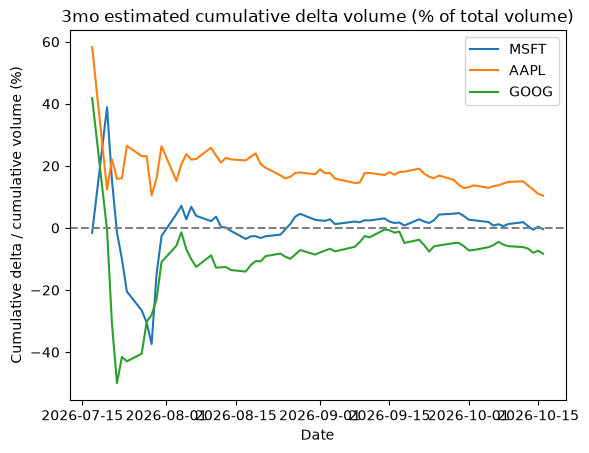

In [4]:
# Estimated (close-location) delta volume, cumulative and normalised by total volume
def delta_vol(volume, close, high, low):
    rng = (high - low)
    clv = ((close - low) / rng).where(rng > 0, 0.5)     # 0.5 -> zero delta when high == low
    delta = volume * (2 * clv - 1)
    return delta.cumsum(), volume.cumsum()

delta_pct = {}
for t in ['MSFT', 'AAPL', 'GOOG']:
    cum_delta, cum_vol = delta_vol(data.Volume[t], data.Close[t], data.High[t], data.Low[t])
    delta_pct[t] = cum_delta / cum_vol * 100
    plt.plot(data.index, delta_pct[t], label=f'{t}')
print({t: round(float(v.iloc[-1]), 1) for t, v in delta_pct.items()})

plt.legend()
plt.title(f'{Period} estimated cumulative delta volume (% of total volume)')
plt.xlabel('Date')
plt.ylabel('Cumulative delta / cumulative volume (%)')
plt.axhline(y=0, color='gray', linestyle='--')

plt.show()
